# Labor Market Polarization under Differential AI Exposure
### Notebook 2: Analytical Calibration, Simulation-Based Calibration, and Sensitivity Analysis

**Course:** Computational Economics (A.Y. 2025-2026)

**Institutions:** Sant'Anna School of Advanced Studies & University of Pisa

**Professors:** Prof. G. Fagiolo, Prof. A. Roventini, Prof. A. Vandin

**Students:**
* Lucia D'Amore
* Nora Donelli
* Silvia Pagliarulo
* Sofia Perondi

---

### Notebook overview

This notebook documents every model parameter obtained through a numerical procedure, together with the associated robustness analysis. Three distinct exercises are reported, in order.

1. **Analytical calibration (Part I).** Parameters whose model-implied moment has a closed-form expression are recovered by root-finding: the Bass (1969) diffusion coefficients $\lambda_0$ and $\gamma$, and the learning-by-doing parameters $\rho$ and $\pi_{\max}$. These values are empirically anchored (category E in the parameter table, see the paper for references) and solved here by an equation.
2. **Simulation-based calibration (Part II).** Parameters with no closed-form mapping to their target moment are estimated by grid search over the full agent-based model, minimizing the distance between simulated and empirical moments -- Simulated Method of Moments (SMM): the displacement probabilities $p_J$, $p_S$, and the underemployment wage penalty $\psi$ (category C). **All simulation-based calibration is carried out on Model 2** ($\gamma = 0.032$, the Axelrod/Bass mean-field imitation specification), since Model 2 is the specification whose adoption path ($F(36) \approx 0.46$) reproduces the empirical episode from which the displacement and wage targets are themselves drawn. Model 1 ($\gamma = 0$) inherits $p_J$, $p_S$, $\psi$ as a theoretical counterfactual and is not separately recalibrated.
3. **Sensitivity analysis (Part III).** $S_{\text{des}}$ and $\delta$ (patience decay) have no empirical counterpart to target, so instead of estimating a point value the notebook verifies that the model's qualitative findings (Gini rising meaningfully above zero, polarization rising above 1) are robust across a plausible grid, with every other calibrated parameter held at its Part I/II value.

Throughout, one simulation step corresponds to one month. The empirical horizon used for the calibration targets in Parts II-III (October 2022 - September 2025) is **36 steps**; this is distinct from the longer production horizon (150 steps) used elsewhere in the project to let post-adoption dynamics fully unfold.

### Imports and shared settings

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import warnings
warnings.filterwarnings("ignore")  # silences all-NaN slices before any worker is displaced

from mesa import Agent, Model
from mesa.datacollection import DataCollector
from scipy.optimize import brentq, root_scalar

mpl.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["Palatino Linotype", "Palatino", "Book Antiqua", "serif"],
    "mathtext.fontset": "stix",
    "axes.titlesize":   12,
    "axes.labelsize":   11,
    "xtick.labelsize":  10,
    "ytick.labelsize":  10,
    "legend.fontsize":  9,
    "figure.dpi":       120,
})

# QUICK_TEST = True runs a fast, low-resolution pass (coarse grids, few seeds, small
# population) to verify that the notebook executes end to end in under a minute.
# QUICK_TEST = False runs the full-resolution calibration reported in the paper.
QUICK_TEST = False   # <-- set to False for the final run

SEED = 42


## Model 2 specification (Axelrod / Bass mean-field imitation)

The agent and model code below reproduces the Model 2 specification with one structural extension needed for calibration: the displacement probabilities `p_junior`, `p_senior`, and the underemployment penalty `underemployment_penalty` are promoted from hardcoded literals to constructor keyword arguments, defaulting to their currently calibrated values.

Two employment-count reporters (`N_Junior_Employed`, `N_Senior_Employed`) and the two $t=0$ cohort sizes (`n0_junior`, `n0_senior`) are added to the model for the same reason: Part II needs them to compute the employment-change moments.

In [2]:
class WorkerAgent(Agent):
    """Worker labelled Junior or Senior, subject to AI-driven displacement.
    Reproduced unchanged from Notebook 1 / Notebook 3."""

    def __init__(self, model, seniority, initial_savings):
        super().__init__(model=model)
        self.seniority = seniority
        self.savings = initial_savings
        self.skills = 1.0
        self.employed = True
        self.status = "Employed"
        self.employer = None
        self.unemployment_duration = 0
        self.did_retrain = False
        self.was_ever_displaced = False
        self.hired_without_retraining = False
        self.retraining_timer = 0
        self.last_wage = model.wage_baseline
        self.savings_rate = model.savings_rate_base
        self.hiring_weight = 1.0
        self.retraining_decision_made = False

    def receive_wage(self, wage):
        """Buffer-stock savings rule: the rate rises with the wage relative to
        the economy-wide baseline (Deaton, 1991; Carroll, 1997). The consumed
        share flows back to the employer's capital, closing the monetary loop."""
        self.last_wage = wage
        wage_ratio = wage / self.model.wage_baseline
        raw_rate = self.model.savings_rate_base + self.model.beta_savings * (wage_ratio - 1)
        self.savings_rate = min(max(raw_rate, self.model.savings_rate_min),
                                 self.model.savings_rate_max)
        self.savings += wage * self.savings_rate
        if self.employer:
            self.employer.capital += wage * (1 - self.savings_rate)

    def step(self):
        # Employed workers are passive within the worker phase.
        if self.status == "Employed":
            return

        self.unemployment_duration += 1

        # Subsistence consumption, capped at available savings (no borrowing).
        consumption = min(self.model.subsistence_cost, max(self.savings, 0.0))
        self.savings -= consumption
        per_firm = consumption / len(self.model.firms_pool)
        for firm in self.model.firms_pool:
            firm.capital += per_firm

        # Retraining in progress: on completion, skills and hiring signal rise.
        if self.status == "Retraining":
            self.retraining_timer -= 1
            if self.retraining_timer <= 0:
                self.skills += self.model.skill_gain
                self.hiring_weight = self.model.retrain_signal_weight
                self.did_retrain = True
                self.status = "Unemployed"
            return

        # Retraining decision, evaluated once at first displacement (buffer-stock
        # threshold): only workers above Theta can afford Path A.
        if self.status == "Unemployed" and not self.retraining_decision_made:
            self.retraining_decision_made = True
            if self.savings >= self.model.retraining_threshold:
                self.status = "Retraining"
                self.retraining_timer = self.model.retraining_duration
                fee = self.model.training_cost
                self.savings -= fee
                per_firm_f = fee / len(self.model.firms_pool)
                for firm in self.model.firms_pool:
                    firm.capital += per_firm_f


In [3]:
class FirmAgent(Agent):
    """Firm with a per-firm AI-adoption hazard (innovation + imitation),
    learning-by-doing productivity, and profit-sharing markup wages.
    `firing_rule` reads p_junior / p_senior from the model instance instead of
    hardcoded literals, so the two probabilities can be treated as free
    parameters in Part II without maintaining a second copy of this class."""

    def __init__(self, model, initial_capital):
        super().__init__(model=model)
        self.capital = initial_capital
        self.employees_list = []
        self.firm_revenue = model.revenue_0
        self.ai_unlocked = False
        self.already_fired = False
        self.productivity = 1.0
        self.automation_level = 0.0
        self.desired_skill = model.desired_skill
        self.patience = 0
        self.target_size = 0
        self.base_productivity = 1.0

    # AI ARRIVAL: Poisson innovation + mean-field imitation (Axelrod / Bass, 1969)
    def check_ai_arrival(self):
        """lambda_i(t) = lambda_0 + gamma * F(t); F(t) is fixed once per step."""
        if not self.ai_unlocked:
            rate = self.model.lambda_ai + self.model.gamma * self.model.adoption_share
            p = 1 - np.exp(-rate)
            if self.random.random() < p:
                self.ai_unlocked = True

    # PRODUCTIVITY: learning-by-doing, scaled by current workforce skill
    def update_productivity(self):
        if self.ai_unlocked:
            self.base_productivity += self.model.rho * (self.model.pi_max - self.base_productivity)
            media_skills = (sum(w.skills for w in self.employees_list) / len(self.employees_list)
                            if self.employees_list else 1.0)
            self.productivity = self.base_productivity * media_skills

    # REVENUE: net of the fixed AI operating cost, floored at zero
    def update_revenue(self):
        revenue_0 = self.model.revenue_0
        if self.ai_unlocked:
            gross = revenue_0 * self.productivity
            self.firm_revenue = max(gross - self.model.ca_fixed, 0.0)
        else:
            self.firm_revenue = revenue_0

    # WAGES: profit-sharing markup, with a penalty for Path-B (unreskilled) re-hires
    def distribute_wages(self):
        w0 = self.model.wage_baseline
        if self.firm_revenue > self.model.revenue_0:
            base_wage = w0 * (1 + self.model.theta *
                        (self.firm_revenue - self.model.revenue_0) / self.model.revenue_0)
        else:
            base_wage = w0
        for worker in self.employees_list:
            current_wage = (base_wage * self.model.underemployment_penalty
                            if worker.hired_without_retraining else base_wage)
            self.capital -= current_wage
            worker.receive_wage(current_wage)

    # FIRING: one-off displacement by AI exposure (Brynjolfsson, Chandar & Chen, 2025)
    def firing_rule(self):
        self.automation_level = 1.0
        for worker in list(self.employees_list):
            # p_junior / p_senior read from the model instance (ADDED: previously
            # hardcoded as 0.75 / 0.02 literals inside this method).
            exposure = self.model.p_junior if worker.seniority == "Junior" else self.model.p_senior
            if self.random.random() < exposure:
                self.model.cumulative_displaced += 1
                worker.was_ever_displaced = True
                if worker.seniority == "Junior":
                    self.model.fired_junior_step += 1
                else:
                    self.model.fired_senior_step += 1
                worker.employed = False
                worker.status = "Unemployed"
                worker.employer = None
                self.employees_list.remove(worker)

    # HIRING: signalling draw plus a patience-eroded skill reservation (Spence, 1973)
    def evaluate_hiring(self):
        if not self.ai_unlocked:
            return
        if self.capital < self.model.wage_baseline * self.model.hire_buffer:
            return
        if len(self.employees_list) >= self.target_size:
            return
        pool = self.model.get_unemployed_pool()
        if not pool:
            return
        weights = [w.hiring_weight for w in pool]
        candidate = self.random.choices(pool, weights=weights, k=1)[0]
        reservation = self.desired_skill - self.patience * self.model.patience_decay
        if candidate.skills >= reservation:
            self.hire(candidate)
            self.patience = 0
        else:
            self.patience += 1

    def hire(self, worker):
        worker.employer = self
        worker.employed = True
        worker.status = "Employed"
        worker.hired_without_retraining = not worker.did_retrain
        if worker.did_retrain:
            self.model.hired_skilled_step += 1
        else:
            self.model.hired_unskilled_step += 1
        self.employees_list.append(worker)

    def step(self):
        self.check_ai_arrival()
        self.update_productivity()
        self.update_revenue()
        self.capital += self.firm_revenue
        self.distribute_wages()
        if self.ai_unlocked and not self.already_fired:
            self.firing_rule()
            self.already_fired = True
        self.evaluate_hiring()


In [4]:
class AutomationModel(Model):
    """Model 2 specification: Poisson innovation + Bass/Axelrod mean-field
    imitation. Reproduced from Notebook 1 / Notebook 3, with three additions
    (each flagged inline) needed for the calibration carried out below:

      1. p_junior, p_senior, underemployment_penalty are constructor kwargs
         instead of hardcoded literals inside FirmAgent.
      2. N_Junior_Employed / N_Senior_Employed reporters are added to the
         DataCollector.
      3. n0_junior / n0_senior (t = 0 cohort sizes) are stored as fixed
         denominators for the employment-change moments in Part II.

    None of these additions changes the model's dynamics when run at the
    default parameter values -- they only expose what was already computed
    internally, or promote literals to defaults-preserving kwargs."""

    def __init__(self, num_firms=100, num_workers=1000, initial_firm_capital=1000.0,
                 initial_worker_savings=0.0, wage_baseline=20.0, savings_rate=0.20,
                 beta_savings=0.058, savings_rate_min=0.0, savings_rate_max=0.25,
                 revenue_0=400.0, senior_ratio=0.3, lambda_ai=0.010097,
                 gamma=0.0320,               # Model 2 default: gamma > 0 (Axelrod/Bass imitation)
                 rho=0.017, pi_max=1.378,
                 ca_fixed=1.22, theta=0.35, hire_buffer=3.0,
                 patience_decay=0.05, desired_skill=1.3,
                 subsistence_cost=10, training_cost=60, retrain_signal_weight=2.0,
                 buffer_months=3,
                 p_junior=0.75, p_senior=0.02,          # ADDED: was hardcoded in firing_rule
                 underemployment_penalty=0.83,          # ADDED: was a bare literal below
                 seed=None):
        super().__init__(seed=seed)

        # Exogenous parameters
        self.wage_baseline = wage_baseline
        self.savings_rate_base = savings_rate
        self.beta_savings = beta_savings
        self.savings_rate_min = savings_rate_min
        self.savings_rate_max = savings_rate_max
        self.revenue_0 = revenue_0
        self.lambda_ai = lambda_ai
        self.gamma = gamma
        self.adoption_share = 0.0
        self.rho = rho
        self.pi_max = pi_max
        self.ca_fixed = ca_fixed
        self.theta = theta
        self.hire_buffer = hire_buffer
        self.patience_decay = patience_decay
        self.desired_skill = desired_skill
        self.subsistence_cost = subsistence_cost
        self.retraining_duration = 3
        self.training_cost = training_cost
        self.buffer_months = buffer_months
        # Theta = retraining living cost + upfront fee + precautionary buffer
        self.retraining_threshold = (self.retraining_duration * self.subsistence_cost
                                      + self.training_cost
                                      + self.wage_baseline * self.buffer_months)
        self.skill_gain = 0.3
        self.underemployment_penalty = underemployment_penalty
        self.p_junior = p_junior
        self.p_senior = p_senior
        self.current_step = 0
        self.retrain_signal_weight = retrain_signal_weight
        self.cumulative_displaced = 0
        self.hired_skilled_step = 0
        self.hired_unskilled_step = 0
        self.fired_junior_step = 0
        self.fired_senior_step = 0

        # Data collection
        emp = lambda m, s: [w for w in m.agents if isinstance(w, WorkerAgent)
                            and w.seniority == s and w.status == "Employed"]
        allw = lambda m, s: [w for w in m.agents if isinstance(w, WorkerAgent) and w.seniority == s]
        self.datacollector = DataCollector(model_reporters={
            "Gini":                 lambda m: m.calculate_gini,
            "Gini_Savings_Junior":  lambda m: m.calculate_gini_savings_junior,
            "Polarization":         lambda m: m.calculate_enhanced_polarization,
            "Firms_Automated":      lambda m: sum(1 for f in m.agents
                if isinstance(f, FirmAgent) and f.ai_unlocked),
            "N_Unemployed":         lambda m: sum(1 for w in m.agents
                if isinstance(w, WorkerAgent) and w.status == "Unemployed"),
            # ADDED: employment counts by seniority, needed to compute
            # Delta_Junior / Delta_Senior in Part II.
            "N_Junior_Employed":    lambda m: len(emp(m, "Junior")),
            "N_Senior_Employed":    lambda m: len(emp(m, "Senior")),
            "Mean_Wage_Junior":     lambda m: (np.mean([w.last_wage for w in emp(m, "Junior")])
                if emp(m, "Junior") else np.nan),
            "Mean_Wage_Senior":     lambda m: (np.mean([w.last_wage for w in emp(m, "Senior")])
                if emp(m, "Senior") else np.nan),
            "Mean_Savings_Junior":  lambda m: (np.mean([w.savings for w in allw(m, "Junior")])
                if allw(m, "Junior") else np.nan),
            "Mean_Savings_Senior":  lambda m: (np.mean([w.savings for w in allw(m, "Senior")])
                if allw(m, "Senior") else np.nan),
            "Frac_Reskilled_AmongDisplaced": lambda m: (
                sum(1 for w in m.agents if isinstance(w, WorkerAgent)
                    and w.was_ever_displaced and w.did_retrain)
                / sum(1 for w in m.agents if isinstance(w, WorkerAgent) and w.was_ever_displaced)
                if any(isinstance(w, WorkerAgent) and w.was_ever_displaced for w in m.agents)
                else np.nan),
        })

        # Create firms, then workers assigned to firms (bipartite labor graph)
        for _ in range(num_firms):
            FirmAgent(self, initial_firm_capital)
        self.firms_pool = [a for a in self.agents if isinstance(a, FirmAgent)]
        for _ in range(num_workers):
            seniority = "Senior" if self.random.random() < senior_ratio else "Junior"
            worker = WorkerAgent(self, seniority, initial_worker_savings)
            firm = self.random.choice(self.firms_pool)
            worker.employer = firm
            firm.employees_list.append(worker)
        for f in self.firms_pool:
            f.target_size = len(f.employees_list)

        # ADDED: t = 0 cohort sizes, fixed denominators for the employment-change
        # moments used to calibrate p_junior / p_senior in Part II.
        self.n0_junior = sum(1 for w in self.agents
                              if isinstance(w, WorkerAgent) and w.seniority == "Junior")
        self.n0_senior = sum(1 for w in self.agents
                              if isinstance(w, WorkerAgent) and w.seniority == "Senior")

        self.running = True
        self.datacollector.collect(self)

    def get_unemployed_pool(self):
        """Workers available for hire: unemployed and not currently retraining."""
        return [w for w in self.agents
                if isinstance(w, WorkerAgent) and w.status == "Unemployed"]

    # Metrics
    @property
    def calculate_gini(self):
        """Gini coefficient over all worker savings (0 = equality)."""
        x = sorted(w.savings for w in self.agents if isinstance(w, WorkerAgent))
        n = len(x)
        if sum(x) == 0:
            return 0.0
        b = sum(xi * (n - i) for i, xi in enumerate(x)) / (n * sum(x))
        return 1 + (1 / n) - 2 * b

    @property
    def calculate_enhanced_polarization(self):
        """Senior/Junior mean-savings ratio; equals 1.0 under no differential exposure."""
        workers = [w for w in self.agents if isinstance(w, WorkerAgent)]
        if not workers:
            return 1.0
        senior_s = [w.savings for w in workers if w.seniority == "Senior"]
        junior_s = [w.savings for w in workers if w.seniority == "Junior"]
        if not senior_s or not junior_s:
            return 1.0
        mu_j = np.mean(junior_s)
        return np.mean(senior_s) / mu_j if mu_j > 0 else np.nan

    @property
    def calculate_gini_savings_junior(self):
        """Gini coefficient over Junior workers' savings only."""
        x = sorted(w.savings for w in self.agents
                   if isinstance(w, WorkerAgent) and w.seniority == "Junior")
        n = len(x)
        if sum(x) == 0:
            return 0.0
        b = sum(xi * (n - i) for i, xi in enumerate(x)) / (n * sum(x))
        return 1 + (1 / n) - 2 * b

    # Step: firms act first (revenue, wages, fire, hire), then workers react
    def step(self):
        self.current_step += 1
        self.hired_skilled_step = 0
        self.hired_unskilled_step = 0
        self.fired_junior_step = 0
        self.fired_senior_step = 0
        # F(t) computed once, before firms act (synchronous mean field)
        self.adoption_share = sum(1 for f in self.firms_pool if f.ai_unlocked) / len(self.firms_pool)
        self.agents.select(agent_type=FirmAgent).shuffle_do("step")
        self.agents.select(agent_type=WorkerAgent).shuffle_do("step")
        self.datacollector.collect(self)


## Part I: Analytical calibration (root-finding)

Two parameter pairs are pinned down by inverting a closed-form expression against an empirical moment via a numerical root-finder. The "model" being solved is the deterministic equation itself, so the result is exact up to the root-finder's numerical tolerance.

### I.1 Calibration of $\gamma$ and $\lambda_0$ (Bass, 1969)

These two parameters jointly govern the per-firm AI-adoption hazard,
$$
\lambda_i(t) = \lambda_0 + \gamma \cdot F(t),
$$
where $\lambda_0$ is the *autonomous innovation* coefficient (firms adopt independently of the market, e.g. due to idiosyncratic exposure) and $\gamma \cdot F(t)$ is the *imitation* channel (firms adopt in response to observing competitors who have already adopted, $F(t)$ being the share of already-automated firms at the start of step $t$).

**Step 1 -- fix $\gamma$ from a Bass meta-analysis.** Sultan, Farley and Lehmann (1990) meta-analyse 213 Bass diffusion estimates across a wide range of products and technologies, reporting a mean imitation coefficient of $q \approx 0.38$ per year. Converting to a monthly step frequency gives $\gamma = 0.38 / 12 \approx 0.032$.

**Step 2 -- solve analytically for $\lambda_0$.** We target the empirical adoption moment from Brynjolfsson, Chandar and Chen (2025): approximately 46% of firms had adopted AI tools by mid-2025, i.e. $F(36) \approx 0.46$ at $T = 36$ steps (October 2022 to September 2025). Inverting the Bass cumulative distribution function,
$$
F(T) = \frac{1 - e^{-(\lambda_0 + \gamma)T}}{1 + \frac{\gamma}{\lambda_0} e^{-(\lambda_0 + \gamma)T}} = 0.46,
$$
for $\lambda_0$ requires a numerical root-finder (`scipy.optimize.brentq`), since the equation is not analytically invertible in closed form for $\lambda_0$.

In [5]:
# Calibration of gamma and lambda_0 (Bass, 1969)

def bass_cdf(T, p, q):
    """Bass cumulative adoption share at time T, given innovation rate p and
    imitation rate q."""
    return (1 - np.exp(-(p + q) * T)) / (1 + (q / p) * np.exp(-(p + q) * T))

GAMMA = 0.032          # Bass q, fixed from Sultan, Farley & Lehmann (1990): 0.38/year -> 0.032/month
TARGET_F = 0.46        # Brynjolfsson, Chandar & Chen (2025): ~46% adoption by month 36
T_TARGET = 36

# Solve bass_cdf(36, lambda_0, GAMMA) = TARGET_F for lambda_0
LAMBDA_0 = brentq(lambda p: bass_cdf(T_TARGET, p, GAMMA) - TARGET_F, 1e-6, 0.5)

print(f"gamma     = {GAMMA:.4f}  (Bass q, fixed from Sultan et al. 1990)")
print(f"lambda_0  = {LAMBDA_0:.6f}  (solved analytically)")
print(f"Verify F(36) = {bass_cdf(T_TARGET, LAMBDA_0, GAMMA):.4f}  (target {TARGET_F:.2f})")
print(f"q/p ratio = {GAMMA / LAMBDA_0:.2f}")


gamma     = 0.0320  (Bass q, fixed from Sultan et al. 1990)
lambda_0  = 0.010097  (solved analytically)
Verify F(36) = 0.4600  (target 0.46)
q/p ratio = 3.17


### I.2 Calibration of $\rho$ and $\pi_{\max}$ (learning-by-doing)

Firm productivity converges geometrically to an asymptotic ceiling $\pi_{\max}$ at speed $\rho$:
$$
\pi(t) = \pi_{\max} - (\pi_{\max} - 1)(1 - \rho)^t.
$$
Two empirical moments jointly identify the pair $(\rho, \pi_{\max})$:

- **Moment 1:** the productivity gain reaches 90% of its asymptotic ceiling after $t_1 = 60$ months (5 years).
- **Moment 2:** Brynjolfsson et al. (2025) report a 14% labor productivity gain at $t_2 = 30$ months (2.5 years), i.e. $\pi(30) = 1.14$.

Substituting Moment 1 into the productivity equation and solving for $\rho$ as a function of $\pi_{\max}$ gives a one-dimensional equation in $\pi_{\max}$ alone (Equation 11 in the calibration note), solved by `scipy.optimize.root_scalar`; $\rho$ is then recovered analytically from $\pi_{\max}$ via Equation 9.

In [ ]:
# Calibration of rho and pi_max (two-moment, closed-form learning-by-doing curve)

t1 = 60          # months; Moment 1 horizon
target_1 = 0.90  # 90% of the ceiling reached at t1

t2 = 30          # months; Moment 2 horizon
m2 = 1.14        # 14% productivity gain at t2 (Brynjolfsson et al., 2025)


def objective_function(pi_max):
    """Equation (11): root at the pi_max value consistent with both moments."""
    decay = ((pi_max * (1 - target_1)) / (pi_max - 1)) ** (t2 / t1)
    return pi_max - (pi_max - 1) * decay - m2


# pi_max must be strictly greater than 1 (denominator constraint); [1.001, 5.0]
# is a generous, economically plausible bracket.
result = root_scalar(objective_function, bracket=[1.001, 5.0], method="brentq")
PI_MAX = result.root

# Equation (9): rho as a function of the calibrated pi_max
RHO = 1 - ((PI_MAX * (1 - target_1)) / (PI_MAX - 1)) ** (1 / t1)


def get_productivity(t, p_max, r):
    return p_max - (p_max - 1) * ((1 - r) ** t)


pi_at_t2 = get_productivity(t2, PI_MAX, RHO)
pi_at_t1_ratio = get_productivity(t1, PI_MAX, RHO) / PI_MAX

print("=== TWO-MOMENT CALIBRATION RESULTS ===")
print(f"Productivity ceiling (pi_max): {PI_MAX:.4f}")
print(f"Learning speed (rho)         : {RHO:.4f}")
print("\n--- MOMENT TARGET VERIFICATION ---")
print(f"Moment 1 (step {t1} >= {target_1:.0%} of pi_max): {pi_at_t1_ratio:.2%} [target: {target_1:.0%}]")
print(f"Moment 2 (step {t2} = m2)                : {pi_at_t2:.4f} [target: {m2:.2f}]")



=== TWO-MOMENT CALIBRATION RESULTS ===
Productivity ceiling (pi_max): 1.3621
Learning speed (rho)         : 0.0162

--- MOMENT TARGET VERIFICATION ---
Moment 1 (step 60 >= 90% of pi_max): 90.00% [target: 90%]
Moment 2 (step 30 = m2)                : 1.1400 [target: 1.14]

NOTE: compare PI_MAX above against the paper's Table 1 value (1.362) before treating this as final -- see the markdown cell above.


## Part II: Simulation-based calibration on Model 2 (Simulated Method of Moments)

For $p_J$, $p_S$, and $\psi$ we use the **Simulated Method of Moments (SMM)**: for each candidate parameter value, simulate the ABM over many seeds, average the resulting moment to integrate out simulation noise, and choose the value that minimizes squared distance to the empirical target. The standard error of the simulated moment (`se_junior`, `se_senior`, `se_wage_gap` below) reports the Monte Carlo sampling uncertainty this procedure carries: something the analytical calibration in Part I does not need to report, since it has none.

**Sequencing within Part II.** $p_J$, $p_S$ are calibrated first (Section II.1), holding $\theta$ fixed at its externally-calibrated value (Kline, Petkova, Williams & Zidar, 2019). $\psi$ is calibrated second (Section II.2), holding $p_J$, $p_S$ fixed at the values just estimated. This is a sequential calibration: it is valid only because every "fixed" parameter at each stage is set to its final, model-consistent value, which is exactly what the single shared `AutomationModel` class above guarantees.

In [7]:
# Section II.1 -- calibration of p_junior, p_senior

N_STEPS_CAL = 36        # calibration horizon: ~Oct 2022 - Sep 2025, 1 step = 1 month
                        # (distinct from the T=150 production horizon used elsewhere)

TARGET_JUNIOR = -0.16   # Brynjolfsson et al. (2025), abstract / Fact 4 (firm-time-FE controlled)
TARGET_SENIOR = 0.00    # "employment for experienced workers remained stable"
TARGET_JUNIOR_ALT = -0.20  # robustness target: Fact 1, software developers, raw decline

if QUICK_TEST:
    N_SEEDS_PJPS = 2
    P_JUNIOR_GRID = np.round(np.arange(0.60, 0.91, 0.15), 2)
    P_SENIOR_GRID = np.round(np.arange(0.00, 0.11, 0.05), 2)
    CAL_KWARGS = dict(num_firms=100, num_workers=1000, gamma=GAMMA,
                      pi_max=PI_MAX, rho=RHO, underemployment_penalty=0.85)
else:
    N_SEEDS_PJPS = 15
    P_JUNIOR_GRID = np.round(np.arange(0.60, 0.81, 0.05), 2)
    # Lower bound extended to 0.00 (was 0.02): the previous grid's optimum sat
    # exactly at its lower boundary, so the search is widened to confirm
    # whether the true minimum lies further down.
    P_SENIOR_GRID = np.round(np.arange(0.00, 0.16, 0.02), 2)
    CAL_KWARGS = dict(num_firms=20, num_workers=200, gamma=GAMMA,
                      pi_max=PI_MAX, rho=RHO, underemployment_penalty=0.85)


def run_once_pjps(p_junior, p_senior, seed, n_steps=N_STEPS_CAL):
    """Return (delta_junior, delta_senior): the percentage change in employment
    relative to t=0 for each cohort, simulated under Model 2 (gamma fixed)."""
    model = AutomationModel(p_junior=p_junior, p_senior=p_senior, seed=seed, **CAL_KWARGS)
    for _ in range(n_steps):
        model.step()
    df = model.datacollector.get_model_vars_dataframe()
    n_j_end = df["N_Junior_Employed"].iloc[-1]
    n_s_end = df["N_Senior_Employed"].iloc[-1]
    delta_junior = n_j_end / model.n0_junior - 1.0
    delta_senior = n_s_end / model.n0_senior - 1.0
    return delta_junior, delta_senior


def grid_search_pjps(target_junior=TARGET_JUNIOR, target_senior=TARGET_SENIOR,
                      weight_junior=1.0, weight_senior=1.0):
    """SMM grid search: for each (p_junior, p_senior) pair, average the
    simulated employment-change moments over N_SEEDS_PJPS seeds and minimize
    the weighted squared distance to the empirical targets."""
    rows = []
    total_pairs = len(P_JUNIOR_GRID) * len(P_SENIOR_GRID)
    pair_count = 0
    for p_j in P_JUNIOR_GRID:
        for p_s in P_SENIOR_GRID:
            pair_count += 1
            print(f"  [{pair_count}/{total_pairs}] p_J={p_j}, p_S={p_s} ...", flush=True)
            djs, dss = [], []
            for seed in range(N_SEEDS_PJPS):
                dj, ds = run_once_pjps(p_j, p_s, seed=seed)
                djs.append(dj)
                dss.append(ds)
            mean_dj, mean_ds = np.mean(djs), np.mean(dss)
            se_dj = np.std(djs) / np.sqrt(N_SEEDS_PJPS)
            se_ds = np.std(dss) / np.sqrt(N_SEEDS_PJPS)
            loss = (weight_junior * (mean_dj - target_junior) ** 2
                    + weight_senior * (mean_ds - target_senior) ** 2)
            rows.append(dict(p_junior=p_j, p_senior=p_s,
                              delta_junior=mean_dj, se_junior=se_dj,
                              delta_senior=mean_ds, se_senior=se_ds,
                              loss=loss))
    return pd.DataFrame(rows).sort_values("loss").reset_index(drop=True)


In [8]:
print(f"QUICK_TEST = {QUICK_TEST}")
print(f"Model 2 (gamma = {GAMMA}); target: Junior = {TARGET_JUNIOR:.0%}, Senior = {TARGET_SENIOR:.0%}, "
      f"horizon = {N_STEPS_CAL} steps, {N_SEEDS_PJPS} seeds/pair, "
      f"{len(P_JUNIOR_GRID)}x{len(P_SENIOR_GRID)} pairs\n")

results_pjps = grid_search_pjps()
print("\nTop 10 pairs (p_junior, p_senior) by increasing loss:\n")
print(results_pjps.head(10).to_string(index=False))

best_pjps = results_pjps.iloc[0]
P_J_CALIBRATED = best_pjps.p_junior
P_S_CALIBRATED = best_pjps.p_senior
print(f"\n--> Calibrated pair: p_J = {P_J_CALIBRATED}, p_S = {P_S_CALIBRATED}")
print(f"    Simulated Delta_Junior = {best_pjps.delta_junior:+.1%} (target {TARGET_JUNIOR:+.0%})")
print(f"    Simulated Delta_Senior = {best_pjps.delta_senior:+.1%} (target {TARGET_SENIOR:+.0%})")

if P_S_CALIBRATED == P_SENIOR_GRID.min():
    print("\nWARNING: p_S sits at the lower edge of the grid -- this is a boundary "
          "solution, not a confirmed interior optimum. Consider extending "
          "P_SENIOR_GRID further down before reporting this value as final.")

results_pjps.to_csv("grid_search_pJ_pS_model2_results.csv", index=False)
print("\nFull results saved to grid_search_pJ_pS_model2_results.csv")


QUICK_TEST = False
Model 2 (gamma = 0.032); target: Junior = -16%, Senior = 0%, horizon = 36 steps, 15 seeds/pair, 5x8 pairs

  [1/40] p_J=0.6, p_S=0.0 ...
  [2/40] p_J=0.6, p_S=0.02 ...
  [3/40] p_J=0.6, p_S=0.04 ...
  [4/40] p_J=0.6, p_S=0.06 ...
  [5/40] p_J=0.6, p_S=0.08 ...
  [6/40] p_J=0.6, p_S=0.1 ...
  [7/40] p_J=0.6, p_S=0.12 ...
  [8/40] p_J=0.6, p_S=0.14 ...
  [9/40] p_J=0.65, p_S=0.0 ...
  [10/40] p_J=0.65, p_S=0.02 ...
  [11/40] p_J=0.65, p_S=0.04 ...
  [12/40] p_J=0.65, p_S=0.06 ...
  [13/40] p_J=0.65, p_S=0.08 ...
  [14/40] p_J=0.65, p_S=0.1 ...
  [15/40] p_J=0.65, p_S=0.12 ...
  [16/40] p_J=0.65, p_S=0.14 ...
  [17/40] p_J=0.7, p_S=0.0 ...
  [18/40] p_J=0.7, p_S=0.02 ...
  [19/40] p_J=0.7, p_S=0.04 ...
  [20/40] p_J=0.7, p_S=0.06 ...
  [21/40] p_J=0.7, p_S=0.08 ...
  [22/40] p_J=0.7, p_S=0.1 ...
  [23/40] p_J=0.7, p_S=0.12 ...
  [24/40] p_J=0.7, p_S=0.14 ...
  [25/40] p_J=0.75, p_S=0.0 ...
  [26/40] p_J=0.75, p_S=0.02 ...
  [27/40] p_J=0.75, p_S=0.04 ...
  [28/40] p_J=0

### II.2 Calibration of $\psi$ (underemployment wage penalty)

$\theta = 0.35$ (Kline, Petkova, Williams & Zidar, 2019) is fixed directly from its empirical elasticity. $\psi$, by contrast, has no direct empirical counterpart, its effect on the aggregate wage gap depends on the endogenous composition of workers re-hired without retraining, which only the simulation can produce.

**Target.** Fact 5 of Brynjolfsson et al. (2025): the wage divergence between more-/less-exposed groups is much smaller than the employment divergence (16 pp, already calibrated via $p_J$, $p_S$). We target a wage gap of $\text{TARGET\_RATIO} \times \text{employment\_gap} \approx 0.15 \times 0.16 \approx 2.4$ percentage points.

$p_J$, $p_S$ are held fixed at the values calibrated in II.1 (`P_J_CALIBRATED`, `P_S_CALIBRATED`), and `gamma` remains fixed at the Model 2 value.

In [10]:
# Section II.2 -- calibration of psi (underemployment_penalty)

THETA_FIXED = 0.35   # Kline, Petkova, Williams & Zidar (2019); fixed directly, not grid-searched
EMPLOYMENT_GAP_CALIBRATED = abs(TARGET_JUNIOR) - TARGET_SENIOR   # = 0.16
TARGET_RATIO = 0.15
TARGET_WAGE_GAP = TARGET_RATIO * EMPLOYMENT_GAP_CALIBRATED       # ~ 0.024

if QUICK_TEST:
    N_SEEDS_PSI = 2
    PSI_GRID = np.round(np.arange(0.70, 0.96, 0.05), 2)
else:
    N_SEEDS_PSI = 15
    PSI_GRID = np.round(np.arange(0.75, 0.96, 0.01), 2)


def run_once_psi(psi, seed, n_steps=N_STEPS_CAL):
    """Return (wage_gap, employment_gap) at the end of the calibration horizon,
    under Model 2 with p_junior, p_senior fixed at their Section II.1 values."""
    model = AutomationModel(p_junior=P_J_CALIBRATED, p_senior=P_S_CALIBRATED,
                             underemployment_penalty=psi, theta=THETA_FIXED,
                             seed=seed, **CAL_KWARGS)
    for _ in range(n_steps):
        model.step()
    df = model.datacollector.get_model_vars_dataframe()

    n_j_end = df["N_Junior_Employed"].iloc[-1]
    n_s_end = df["N_Senior_Employed"].iloc[-1]
    delta_junior_emp = n_j_end / model.n0_junior - 1.0
    delta_senior_emp = n_s_end / model.n0_senior - 1.0
    employment_gap = delta_senior_emp - delta_junior_emp

    w0 = model.wage_baseline
    w_j_end = df["Mean_Wage_Junior"].iloc[-1]
    w_s_end = df["Mean_Wage_Senior"].iloc[-1]
    wage_growth_junior = w_j_end / w0 - 1.0
    wage_growth_senior = w_s_end / w0 - 1.0
    wage_gap = wage_growth_senior - wage_growth_junior

    return wage_gap, employment_gap


def grid_search_psi(target_wage_gap=TARGET_WAGE_GAP):
    rows = []
    total = len(PSI_GRID)
    count = 0
    for psi in PSI_GRID:
        count += 1
        print(f"  [{count}/{total}] psi={psi} ...", flush=True)
        wgs, egs = [], []
        for seed in range(N_SEEDS_PSI):
            wg, eg = run_once_psi(psi, seed=seed)
            wgs.append(wg)
            egs.append(eg)
        mean_wg, mean_eg = np.mean(wgs), np.mean(egs)
        se_wg = np.std(wgs) / np.sqrt(N_SEEDS_PSI)
        loss = (mean_wg - target_wage_gap) ** 2
        rows.append(dict(psi=psi, wage_gap=mean_wg, se_wage_gap=se_wg,
                          employment_gap=mean_eg,
                          ratio=mean_wg / mean_eg if mean_eg != 0 else np.nan,
                          loss=loss))
    return pd.DataFrame(rows).sort_values("loss").reset_index(drop=True)


In [11]:
print(f"QUICK_TEST = {QUICK_TEST}")
print(f"theta = {THETA_FIXED} (fixed, Kline, Petkova, Williams & Zidar 2019)")
print(f"p_J = {P_J_CALIBRATED}, p_S = {P_S_CALIBRATED} (fixed, calibrated in Section II.1)")
print(f"Target wage_gap = {TARGET_WAGE_GAP:.1%} "
      f"({TARGET_RATIO:.0%} of the calibrated employment_gap of {EMPLOYMENT_GAP_CALIBRATED:.0%})")
print(f"Horizon = {N_STEPS_CAL} steps, {N_SEEDS_PSI} seeds/value, {len(PSI_GRID)} psi values\n")

results_psi = grid_search_psi()
print("\nAll tested values, sorted by increasing loss:\n")
print(results_psi.to_string(index=False))

best_psi = results_psi.iloc[0]
PSI_CALIBRATED = best_psi.psi
print(f"\n--> Calibrated psi = {PSI_CALIBRATED}")
print(f"    Simulated wage_gap = {best_psi.wage_gap:+.2%} (target {TARGET_WAGE_GAP:+.1%})")
print(f"    Simulated employment_gap = {best_psi.employment_gap:+.1%} (expected ~{EMPLOYMENT_GAP_CALIBRATED:+.0%})")
print(f"    wage_gap / employment_gap ratio = {best_psi.ratio:.3f} (target {TARGET_RATIO:.2f})")

results_psi.to_csv("grid_search_psi_model2_results.csv", index=False)
print("\nFull results saved to grid_search_psi_model2_results.csv")


QUICK_TEST = False
theta = 0.35 (fixed, Kline, Petkova, Williams & Zidar 2019)
p_J = 0.6, p_S = 0.0 (fixed, calibrated in Section II.1)
Target wage_gap = 2.4% (15% of the calibrated employment_gap of 16%)
Horizon = 36 steps, 15 seeds/value, 21 psi values

  [1/21] psi=0.75 ...
  [2/21] psi=0.76 ...
  [3/21] psi=0.77 ...
  [4/21] psi=0.78 ...
  [5/21] psi=0.79 ...
  [6/21] psi=0.8 ...
  [7/21] psi=0.81 ...
  [8/21] psi=0.82 ...
  [9/21] psi=0.83 ...
  [10/21] psi=0.84 ...
  [11/21] psi=0.85 ...
  [12/21] psi=0.86 ...
  [13/21] psi=0.87 ...
  [14/21] psi=0.88 ...
  [15/21] psi=0.89 ...
  [16/21] psi=0.9 ...
  [17/21] psi=0.91 ...
  [18/21] psi=0.92 ...
  [19/21] psi=0.93 ...
  [20/21] psi=0.94 ...
  [21/21] psi=0.95 ...

All tested values, sorted by increasing loss:

 psi  wage_gap  se_wage_gap  employment_gap    ratio         loss
0.85   0.02472     0.001446        0.160341 0.154171 5.183254e-07
0.86   0.02322     0.001356        0.160341 0.144816 6.084125e-07
0.84   0.02622     0.00153

## Part III: Sensitivity analysis: $S_{\text{des}}$ and $\delta$ (patience decay)

No empirical source measures firm-level reservation-skill dynamics, so `desired_skill` ($S_{\text{des}}$) and `patience_decay` ($\delta$) cannot be calibrated against a target moment the way $p_J$, $p_S$, and $\psi$ were in Part II. The notebook verifies that the model's qualitative findings, a Gini coefficient that rises meaningfully above zero, and a polarization index that rises above 1,  hold across a plausible grid of $(S_{\text{des}}, \delta)$ combinations.

Every other calibrated parameter is held fixed at its Part I/II value: $p_J$, $p_S$ from Section II.1, $\psi$ from Section II.2, and `gamma` at the Model 2 value. Agreement across the grid is reported as a **robustness result**, it shows that the qualitative mechanism generating inequality and polarization does not depend on a fine-tuned choice of these two frictions.

In [12]:
# Sensitivity grid over S_des and delta, all other calibrated parameters fixed

N_STEPS_SENS = 100
N_SEEDS_SENS = 10 if not QUICK_TEST else 3

if QUICK_TEST:
    sdes_values  = np.round(np.arange(1.15, 1.40, 0.10), 2)
    delta_values = np.round(np.arange(0.02, 0.15, 0.06), 3)
else:
    sdes_values  = np.round(np.arange(1.10, 1.45, 0.05), 2)
    delta_values = np.round(np.arange(0.02, 0.22, 0.04), 3)

BASELINE_SDES  = 1.30
BASELINE_DELTA = 0.05

print(f"Grid: {len(sdes_values)} S_des values x {len(delta_values)} delta values "
      f"x {N_SEEDS_SENS} seeds = {len(sdes_values) * len(delta_values) * N_SEEDS_SENS} total runs")
print(f"S_des values: {list(sdes_values)}")
print(f"delta values: {list(delta_values)}")
print(f"Fixed at their calibrated values: p_J={P_J_CALIBRATED}, p_S={P_S_CALIBRATED}, "
      f"psi={PSI_CALIBRATED}, gamma={GAMMA}")

records = []
total = len(sdes_values) * len(delta_values)
counter = 0

for sdes in sdes_values:
    for delta in delta_values:
        counter += 1
        print(f"[{counter}/{total}] S_des={sdes:.2f}, delta={delta:.2f}", end="\r")

        ginis, polarizations, n_reskilled_shares = [], [], []

        for seed in range(N_SEEDS_SENS):
            m = AutomationModel(
                desired_skill=sdes,
                patience_decay=delta,
                p_junior=P_J_CALIBRATED,
                p_senior=P_S_CALIBRATED,
                underemployment_penalty=PSI_CALIBRATED,
                gamma=GAMMA,
                seed=seed,
            )
            for _ in range(N_STEPS_SENS):
                m.step()

            df_run = m.datacollector.get_model_vars_dataframe()
            ginis.append(df_run["Gini"].iloc[-1])
            polarizations.append(df_run["Polarization"].iloc[-1])

            workers_total = sum(1 for w in m.agents if isinstance(w, WorkerAgent))
            workers_skilled = sum(1 for w in m.agents
                                   if isinstance(w, WorkerAgent) and w.did_retrain)
            n_reskilled_shares.append(workers_skilled / workers_total if workers_total > 0 else 0)

        records.append({
            "S_des": sdes, "delta": delta,
            "is_baseline": (sdes == BASELINE_SDES and delta == BASELINE_DELTA),
            "Gini_mean": np.mean(ginis), "Gini_std": np.std(ginis),
            "Pol_mean": np.mean(polarizations), "Pol_std": np.std(polarizations),
            "Reskilled_mean": np.mean(n_reskilled_shares),
            "Gini_positive": np.mean([g > 0.05 for g in ginis]),
            "Pol_above1": np.mean([p > 1.05 for p in polarizations]),
        })

df_sens = pd.DataFrame(records)
print("\n\nSENSITIVITY ANALYSIS RESULTS")
print(df_sens[["S_des", "delta", "Gini_mean", "Gini_std", "Pol_mean", "Pol_std",
               "Gini_positive", "Pol_above1"]].to_string(index=False))

df_sens.to_csv("sensitivity_Sdes_delta_model2_results.csv", index=False)
print("\nFull results saved to sensitivity_Sdes_delta_model2_results.csv")


Grid: 7 S_des values x 5 delta values x 10 seeds = 350 total runs
S_des values: [np.float64(1.1), np.float64(1.15), np.float64(1.2), np.float64(1.25), np.float64(1.3), np.float64(1.35), np.float64(1.4)]
delta values: [np.float64(0.02), np.float64(0.06), np.float64(0.1), np.float64(0.14), np.float64(0.18)]
Fixed at their calibrated values: p_J=0.6, p_S=0.0, psi=0.85, gamma=0.032
[35/35] S_des=1.40, delta=0.18

SENSITIVITY ANALYSIS RESULTS
 S_des  delta  Gini_mean  Gini_std  Pol_mean  Pol_std  Gini_positive  Pol_above1
  1.10   0.02   0.130365  0.010723  1.281794 0.029807            1.0         1.0
  1.10   0.06   0.097213  0.004113  1.211712 0.014901            1.0         1.0
  1.10   0.10   0.086299  0.002511  1.183933 0.005690            1.0         1.0
  1.10   0.14   0.086299  0.002511  1.183933 0.005690            1.0         1.0
  1.10   0.18   0.086299  0.002511  1.183933 0.005690            1.0         1.0
  1.15   0.02   0.160348  0.010943  1.350827 0.028033            1.0    

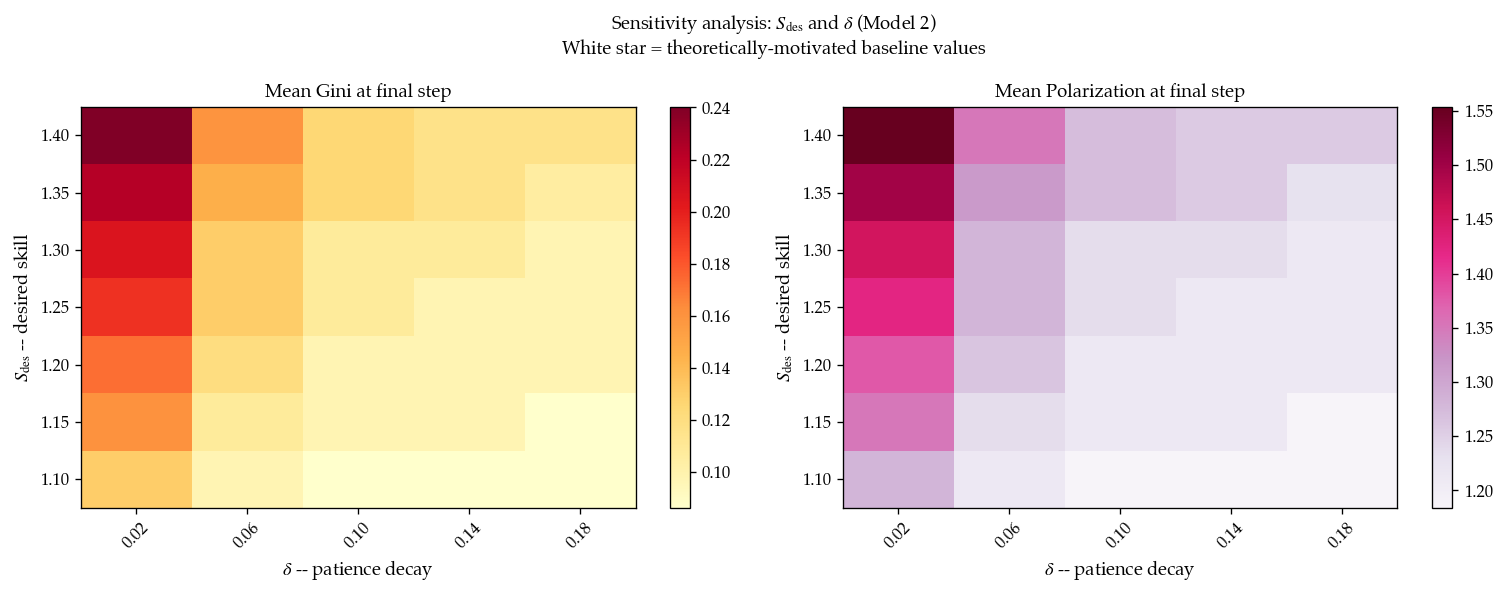


ROBUSTNESS SUMMARY
  Gini > 0.05 in ALL seeds across ALL cells: 35 / 35 cells
  Polarization > 1.05 in ALL seeds across ALL cells: 35 / 35 cells

  Gini range across the entire grid: [0.086, 0.240]
  Polarization range across the entire grid: [1.184, 1.554]


In [13]:
# Heatmaps (Gini, Polarization) and robustness summary

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, title, cmap in zip(
    axes,
    ["Gini_mean", "Pol_mean"],
    ["Mean Gini at final step", "Mean Polarization at final step"],
    ["YlOrRd", "PuRd"],
):
    pivot = df_sens.pivot(index="S_des", columns="delta", values=col)
    im = ax.imshow(pivot.values, aspect="auto", cmap=cmap, origin="lower")
    ax.set_xticks(range(len(delta_values)))
    ax.set_xticklabels([f"{d:.2f}" for d in delta_values], rotation=45)
    ax.set_yticks(range(len(sdes_values)))
    ax.set_yticklabels([f"{s:.2f}" for s in sdes_values])
    ax.set_xlabel(r"$\delta$ -- patience decay", fontsize=11)
    ax.set_ylabel(r"$S_{\mathrm{des}}$ -- desired skill", fontsize=11)
    ax.set_title(title, fontsize=11)
    plt.colorbar(im, ax=ax)

    try:
        d_idx = list(np.round(delta_values, 3)).index(round(BASELINE_DELTA, 3))
        s_idx = list(np.round(sdes_values, 2)).index(round(BASELINE_SDES, 2))
        ax.plot(d_idx, s_idx, "w*", markersize=16,
                label=f"Baseline: S_des={BASELINE_SDES}, delta={BASELINE_DELTA}")
        ax.legend(loc="upper right", fontsize=8)
    except ValueError:
        pass  # baseline not in grid range (e.g. under QUICK_TEST's coarse grid)

plt.suptitle(
    r"Sensitivity analysis: $S_{\mathrm{des}}$ and $\delta$ (Model 2)" + "\n"
    "White star = theoretically-motivated baseline values",
    fontsize=11,
)
plt.tight_layout()
plt.savefig("sensitivity_heatmaps_model2.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nROBUSTNESS SUMMARY")
print(f"  Gini > 0.05 in ALL seeds across ALL cells: "
      f"{(df_sens['Gini_positive'] == 1.0).sum()} / {len(df_sens)} cells")
print(f"  Polarization > 1.05 in ALL seeds across ALL cells: "
      f"{(df_sens['Pol_above1'] == 1.0).sum()} / {len(df_sens)} cells")
print(f"\n  Gini range across the entire grid: "
      f"[{df_sens['Gini_mean'].min():.3f}, {df_sens['Gini_mean'].max():.3f}]")
print(f"  Polarization range across the entire grid: "
      f"[{df_sens['Pol_mean'].min():.3f}, {df_sens['Pol_mean'].max():.3f}]")

base = df_sens[df_sens["is_baseline"]]
if not base.empty:
    print(f"\n  Baseline (S_des={BASELINE_SDES}, delta={BASELINE_DELTA}):")
    print(f"    Gini = {base['Gini_mean'].values[0]:.3f} +/- {base['Gini_std'].values[0]:.3f}")
    print(f"    Pol  = {base['Pol_mean'].values[0]:.3f} +/- {base['Pol_std'].values[0]:.3f}")
